 Latihan 1 Sistem cerdas prediksi kelulusan berbasis kehadiran & tugas

In [3]:
# Mengimpor library pandas untuk mengolah data
import pandas as pd

# Mengimpor fungsi untuk membagi data menjadi data latih dan data uji
from sklearn.model_selection import train_test_split

# Mengimpor Decision Tree dan fungsi untuk menggambar pohon
from sklearn.tree import DecisionTreeClassifier, plot_tree

# Mengimpor fungsi untuk menghitung akurasi
from sklearn.metrics import accuracy_score

# Mengimpor matplotlib untuk membuat visualisasi
import matplotlib.pyplot as plt

In [2]:
# Membuat dataset sesuai data yang ada di modul
data = {
    'Kehadiran': [90, 60, 85, 70, 50, 95, 65, 80, 55, 88],
    'Tugas': [80, 50, 90, 75, 60, 85, 70, 78, 65, 82],
    'Status': [
        'Lulus',
        'Tidak Lulus',
        'Lulus',
        'Lulus',
        'Tidak Lulus',
        'Lulus',
        'Tidak Lulus',
        'Lulus',
        'Tidak Lulus',
        'Lulus'
    ]
}

# Mengubah data menjadi tabel DataFrame
df = pd.DataFrame(data)

# Menampilkan dataset
print(df)

   Kehadiran  Tugas       Status
0         90     80        Lulus
1         60     50  Tidak Lulus
2         85     90        Lulus
3         70     75        Lulus
4         50     60  Tidak Lulus
5         95     85        Lulus
6         65     70  Tidak Lulus
7         80     78        Lulus
8         55     65  Tidak Lulus
9         88     82        Lulus


In [4]:
# X berisi fitur yang digunakan model untuk belajar
X = df[['Kehadiran', 'Tugas']]

# y berisi jawaban/label yang ingin diprediksi
y = df['Status']

# Menampilkan X
print("Data X:")
print(X)

# Menampilkan y
print("\nData y:")
print(y)

Data X:
   Kehadiran  Tugas
0         90     80
1         60     50
2         85     90
3         70     75
4         50     60
5         95     85
6         65     70
7         80     78
8         55     65
9         88     82

Data y:
0          Lulus
1    Tidak Lulus
2          Lulus
3          Lulus
4    Tidak Lulus
5          Lulus
6    Tidak Lulus
7          Lulus
8    Tidak Lulus
9          Lulus
Name: Status, dtype: object


In [6]:
# Membagi data menjadi data latih 80% dan data uji 20%
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

# Menampilkan jumlah data latih dan data uji
print("Jumlah data latih:", len(X_train))
print("Jumlah data uji:", len(X_test))

Jumlah data latih: 8
Jumlah data uji: 2


In [7]:
# Membuat model Decision Tree
model = DecisionTreeClassifier(random_state=42)

# Melatih model menggunakan data latih
model.fit(X_train, y_train)

print("Model berhasil dilatih!")

Model berhasil dilatih!


In [8]:
# Model melakukan prediksi terhadap data uji
y_pred = model.predict(X_test)

# Menghitung akurasi prediksi
akurasi = accuracy_score(y_test, y_pred)

# Menampilkan hasil akurasi
print(f"Akurasi Model: {akurasi * 100:.2f}%")

Akurasi Model: 100.00%


In [9]:
# Membuat data mahasiswa baru
data_baru = [[75, 80]]

# Meminta model memprediksi status mahasiswa baru
hasil = model.predict(data_baru)

# Menampilkan hasil prediksi
print(f"Mahasiswa dengan Kehadiran 75 dan Tugas 80 diprediksi: {hasil[0]}")

Mahasiswa dengan Kehadiran 75 dan Tugas 80 diprediksi: Lulus


/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but DecisionTreeClassifier was fitted with feature names
  warnings.warn(


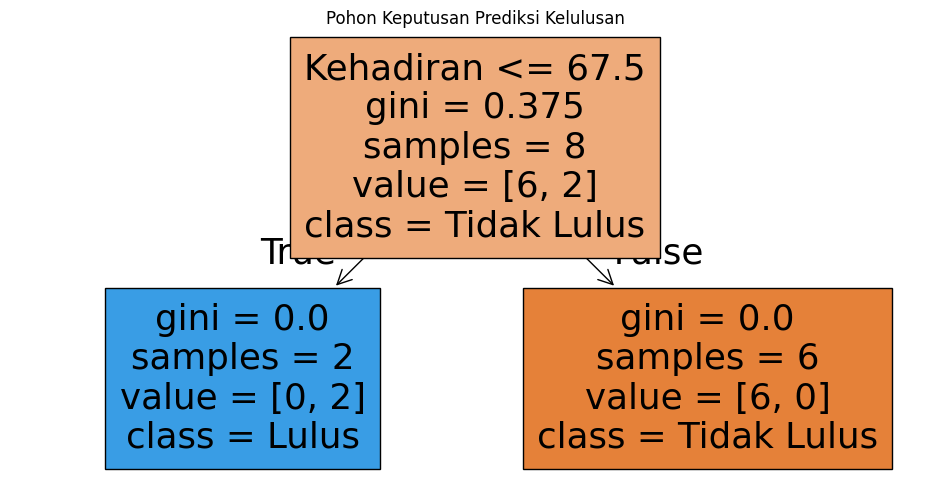

In [10]:
# Menentukan ukuran gambar
plt.figure(figsize=(12, 6))

# Menggambar Decision Tree
plot_tree(
    model,
    feature_names=['Kehadiran', 'Tugas'],
    class_names=['Tidak Lulus', 'Lulus'],
    filled=True
)

# Memberikan judul
plt.title("Pohon Keputusan Prediksi Kelulusan")

# Menampilkan gambar
plt.show()

Hasil program sudah sesuai blueprint. Input berupa dua angka (Kehadiran dan Tugas) dan output berupa label Lulus/Tidak Lulus dalam kalimat, dan ketujuh langkah blueprint (data, split X dan y, split 80:20, training, evaluasi, prediksi, visualisasi) semuanya terwujud di kode. Model mendapat akurasi 100% pada 2 data uji dan prediksi untuk data baru (75, 80) adalah Lulus. Pohon yang terbentuk hanya satu aturan: Kehadiran <= 67.5 maka Tidak Lulus, selain itu Lulus. Ini artinya model memutuskan hanya dari kehadiran, nilai Tugas tidak dipakai sama sekali.
Catatan penting: akurasi 100% ini kurang bisa dipercaya karena data uji hanya 2 data dan datanya sangat sedikit, jadi bukti bahwa model "pintar" masih lemah. Satu perbaikan dari modul: data baru dibuat sebagai DataFrame berkolom agar tidak muncul warning nama fitur, dan class_names memakai model.classes_ supaya urutan label di gambar pohon pasti benar.

Latihan 2 Detektor sentimen positif/negatif untuk ulasan warung

In [12]:
# Mengubah teks menjadi angka menggunakan TF-IDF
from sklearn.feature_extraction.text import TfidfVectorizer

# Menggunakan Naive Bayes sebagai model klasifikasi
from sklearn.naive_bayes import MultinomialNB

In [13]:
# Membuat kumpulan data ulasan
ulasan = [
    "makanannya enak, pelayanan cepat",
    "lama banget, tidak ramah",
    "rasa juara, akan kembali lagi",
    "tempat kotor, kecewa",
    "harga murah enak"
]

# Memberikan label untuk setiap ulasan
label = [
    "Positif",
    "Negatif",
    "Positif",
    "Negatif",
    "Positif"
]

# Menampilkan data
print("Data Ulasan:")
for i in range(len(ulasan)):
    print(ulasan[i], "->", label[i])

Data Ulasan:
makanannya enak, pelayanan cepat -> Positif
lama banget, tidak ramah -> Negatif
rasa juara, akan kembali lagi -> Positif
tempat kotor, kecewa -> Negatif
harga murah enak -> Positif


In [16]:
# Membuat alat untuk mengubah teks menjadi angka
vectorizer = TfidfVectorizer()

# Mempelajari kata-kata dari data ulasan
# kemudian mengubah setiap ulasan menjadi angka
X = vectorizer.fit_transform(ulasan)

# Menampilkan ukuran data hasil TF-IDF
print("Bentuk matriks TF-IDF:", X.shape)

Bentuk matriks TF-IDF: (5, 18)


In [17]:
# Membuat model Naive Bayes
model = MultinomialNB()

# Melatih model menggunakan data hasil TF-IDF
model.fit(X, label)

print("Model Naive Bayes berhasil dilatih!")

Model Naive Bayes berhasil dilatih!


In [18]:
# Membuat ulasan baru yang ingin diprediksi
ulasan_baru = ["pelayanan ramah tapi makanan agak asin"]

# Mengubah ulasan baru menjadi angka
# Menggunakan kamus TF-IDF yang sudah dibuat sebelumnya
X_baru = vectorizer.transform(ulasan_baru)

# Melakukan prediksi
prediksi = model.predict(X_baru)

# Menampilkan hasil prediksi
print(f"Ulasan '{ulasan_baru[0]}' diprediksi: {prediksi[0]}")

Ulasan 'pelayanan ramah tapi makanan agak asin' diprediksi: Positif


Berdasarkan hasil pengujian, sistem klasifikasi sentimen berhasil mengubah data teks menjadi angka menggunakan TF-IDF dan melakukan klasifikasi menggunakan Multinomial Naive Bayes. Ulasan baru “pelayanan ramah tapi makanan agak asin” diprediksi sebagai Positif. Hasil tersebut sudah sesuai dengan blueprint karena input berupa teks dan output berupa sentimen Positif atau Negatif. Namun, model masih memiliki keterbatasan karena jumlah data latihan sangat sedikit.

Latihan 3 Segmentasi pelanggan warung kopi

In [19]:
# Mengimpor pandas untuk membuat dan mengolah tabel data
import pandas as pd

# Mengimpor matplotlib untuk membuat grafik
import matplotlib.pyplot as plt

# Mengimpor K-Means untuk melakukan pengelompokan data
from sklearn.cluster import KMeans

In [20]:
# Membuat data pelanggan sesuai dengan blueprint
data = {
    'Kunjungan': [2, 3, 20, 22, 5, 18],
    'Pengeluaran': [20, 25, 150, 160, 30, 140]
}

# Mengubah data menjadi DataFrame
df = pd.DataFrame(data)

# Menampilkan data pelanggan
print("Data Pelanggan:")
print(df)

Data Pelanggan:
   Kunjungan  Pengeluaran
0          2           20
1          3           25
2         20          150
3         22          160
4          5           30
5         18          140


In [21]:
# Membuat model K-Means dengan 2 kelompok
kmeans = KMeans(
    n_clusters=2,
    random_state=42,
    n_init=10
)

# Melatih model dan memberikan nomor cluster kepada setiap pelanggan
df['Cluster'] = kmeans.fit_predict(
    df[['Kunjungan', 'Pengeluaran']]
)

# Menampilkan hasil pengelompokan
print("Hasil Clustering:")
print(df)

Hasil Clustering:
   Kunjungan  Pengeluaran  Cluster
0          2           20        1
1          3           25        1
2         20          150        0
3         22          160        0
4          5           30        1
5         18          140        0


In [22]:
# Menampilkan titik pusat dari masing-masing cluster
print("Pusat Cluster:")
print(kmeans.cluster_centers_)

Pusat Cluster:
[[ 20.         150.        ]
 [  3.33333333  25.        ]]


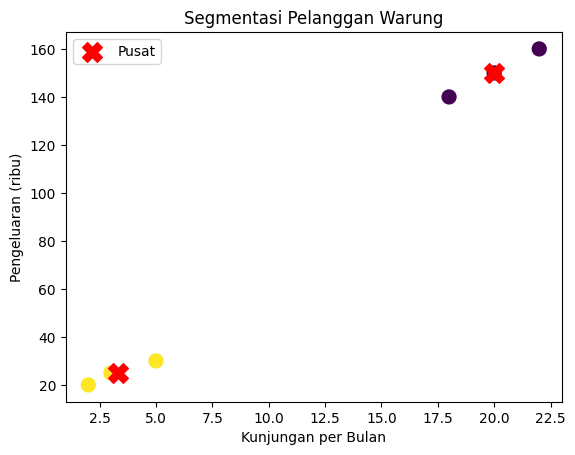

In [23]:
# Membuat grafik berdasarkan jumlah kunjungan dan pengeluaran
plt.scatter(
    df['Kunjungan'],
    df['Pengeluaran'],
    c=df['Cluster'],
    cmap='viridis',
    s=100
)

# Menampilkan titik pusat setiap cluster
plt.scatter(
    kmeans.cluster_centers_[:, 0],
    kmeans.cluster_centers_[:, 1],
    c='red',
    marker='X',
    s=200,
    label='Pusat'
)

# Memberikan nama sumbu X
plt.xlabel('Kunjungan per Bulan')

# Memberikan nama sumbu Y
plt.ylabel('Pengeluaran (ribu)')

# Memberikan judul grafik
plt.title('Segmentasi Pelanggan Warung')

# Menampilkan keterangan grafik
plt.legend()

# Menampilkan grafik
plt.show()

Berdasarkan hasil pengelompokan menggunakan metode K-Means dengan jumlah cluster K=2, data pelanggan berhasil dikelompokkan menjadi dua kelompok berdasarkan jumlah kunjungan dan rata-rata pengeluaran. Kelompok pertama terdiri dari pelanggan dengan jumlah kunjungan dan pengeluaran yang relatif rendah, sedangkan kelompok kedua terdiri dari pelanggan dengan jumlah kunjungan dan pengeluaran yang lebih tinggi. Hasil tersebut sudah sesuai dengan blueprint karena sistem berhasil membentuk dua cluster dan menampilkan visualisasi hasil pengelompokan. Hasil clustering dapat membantu pemilik warung dalam membedakan pelanggan dan menentukan strategi promosi yang sesuai.
